## Problem Statement:

#### Design a fraud detection system to identify fraudulent credit card transactions in real-time.
#### The system should detect suspicious activities such as unauthorized transactions, unusual 
#### spending patterns, and fraudulent card usage to  prevent financial losses for both cardholders 
#### and financial institutions.

In [1]:
# Load library package
import pandas as pd # data tables
import numpy as np # Math
import matplotlib.pyplot as plt # basic graphs
import seaborn as sns # better graphs
#import warnings 
#warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('cc_data_dec19.csv')
print("---"*10)
print("Data has successfully loaded")
print("---"*10)

------------------------------
Data has successfully loaded
------------------------------


In [3]:
df.head()

,index,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,is_fraud
0,910366,29-12-2019 04:03,3.546898e+15,"fraud_Reichert, Shanahan and Hayes",shopping_net,59.62,Kayla,Obrien,F,7921 Robert Port Suite 343,Prairie Hill,TX,76678,31.6591,-96.8094,263,Barrister,30-05-1956,b0e6e23559789dcb5859387f170a440f,0
1,923619,31-12-2019 15:47,4.010002e+15,"fraud_Baumbach, Hodkiewicz and Walsh",shopping_pos,9.52,Jennifer,Bishop,F,589 Matthew Brooks,Houston,TX,77026,29.7972,-95.3288,2906700,Animator,24-08-1983,2132a7ecdd6f86275b545ae04983026f,0
2,879455,22-12-2019 05:38,3.592326e+15,fraud_Friesen-Stamm,gas_transport,75.86,Ashley,Robinson,F,1007 Colton Forks,Hopewell,VA,23860,37.2876,-77.2950,31970,Purchasing manager,15-08-1935,75bad13e134e7273a498b327735ffb31,0
3,869204,19-12-2019 23:26,4.906629e+18,"fraud_Bernhard, Grant and Langworth",shopping_pos,4.03,Charles,Moreno,M,838 Franklin Prairie Apt. 902,Key West,FL,33040,24.6557,-81.3824,32891,Town planner,13-02-1987,4e141388a066af02244f3b01721c97db,0
4,816673,08-12-2019 07:03,3.551218e+15,fraud_Funk Group,grocery_net,42.40,Sara,Harris,F,597 Jenny Ford Apt. 543,Tupper Lake,NY,12986,44.2320,-74.4905,6120,Chartered loss adjuster,09-10-1976,61b06343276629ede9c52798ca078506,0


In [4]:
df.tail(2)

,index,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,is_fraud
42306,916831,30-12-2019 04:30,3.879740e+13,"fraud_Nienow, Ankunding and Collier",misc_pos,38.54,Andrew,Tucker,M,583 Gray Creek,Oak Hill,NY,12460,42.4069,-74.1528,277,Glass blower/designer,12-12-1971,db6e0437f5f6cc6eb75e628792bcd34b,0
42307,843707,14-12-2019 12:24,3.013520e+13,fraud_Barrows PLC,shopping_pos,139.17,Amanda,Williams,F,02018 Gary Key Apt. 911,Independence,MO,64058,39.1412,-94.3515,123373,"Engineer, production",27-11-1992,326bf5da22f1a5ddd2a0be58d1684fac,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42308 entries, 0 to 42307
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   index                  42308 non-null  int64  
 1   trans_date_trans_time  42308 non-null  object 
 2   cc_num                 42308 non-null  float64
 3   merchant               42308 non-null  object 
 4   category               42308 non-null  object 
 5   amt                    42308 non-null  float64
 6   first                  42308 non-null  object 
 7   last                   42308 non-null  object 
 8   gender                 42308 non-null  object 
 9   street                 42308 non-null  object 
 10  city                   42308 non-null  object 
 11  state                  42308 non-null  object 
 12  zip                    42308 non-null  int64  
 13  lat                    42308 non-null  float64
 14  long                   42308 non-null  float64
 15  ci

## 6. Exploratory Data Analysis with Python: 
###  Task 1: What are the dimensions (number of rows and columns) of the dataset?


In [6]:
# To find the dimension of dataframe

print('The dimension of dataset is: ',df.shape)

The dimension of dataset is:  (42308, 20)


### Task 2: How many unique values are there in each categorical variable?

In [7]:
# To get the list of categorical columns

categorical_columns = df.select_dtypes(include = ['object']).columns
print(categorical_columns)

Index(['trans_date_trans_time', 'merchant', 'category', 'first', 'last',
       'gender', 'street', 'city', 'state', 'job', 'dob', 'trans_num'],
      dtype='object')


In [8]:
# Finding out the unique values

for col in categorical_columns:
    print(f'{col} : {df[col].nunique()}')

trans_date_trans_time : 26365
merchant : 693
category : 14
first : 338
last : 465
gender : 2
street : 915
city : 841
state : 50
job : 480
dob : 901
trans_num : 42308


### Task 3: What is the distribution of numerical variables in the dataset?


In [9]:
# Based on domain knowledge and understanding, lets take 'amt' and 'city_pop'
# variables for distribution analysis

df.select_dtypes(include = ['number']).columns
num_df = df[['amt', 'city_pop']].copy()
num_df.head(5)

,amt,city_pop
0,59.62,263
1,9.52,2906700
2,75.86,31970
3,4.03,32891
4,42.40,6120


In [10]:
# Distribution of the columns
num_df.describe()

,amt,city_pop
count,42308.000000,4.230800e+04
mean,70.108462,8.906170e+04
std,188.153737,3.016427e+05
min,1.000000,2.300000e+01
25%,9.590000,7.430000e+02
50%,47.440000,2.456000e+03
75%,82.910000,2.047800e+04
max,27390.120000,2.906700e+06


## Findings:
### 1. mean > median, therefore 'amt' is right skewed distribution
### 2. mean > median, therefore 'city_pop is also right skewed'

### Task 4:Are there any missing values in the dataset?
### If so, how should they be handled?

In [11]:
# Finding missing values
df.isnull().sum()

index                    0
trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
is_fraud                 0
dtype: int64

### Task 5: What are the summary statistics (mean, median, min, max, etc.) 
### for numerical variables?

In [12]:
num_df.describe()

,amt,city_pop
count,42308.000000,4.230800e+04
mean,70.108462,8.906170e+04
std,188.153737,3.016427e+05
min,1.000000,2.300000e+01
25%,9.590000,7.430000e+02
50%,47.440000,2.456000e+03
75%,82.910000,2.047800e+04
max,27390.120000,2.906700e+06


### Task 6: Is there any correlation between numerical variables? 
### If so, how strong is the correlation

In [13]:
# If amount increases → Fraud increases → strong correlation - +1
# If amount increases → Fraud decreases → negative correlation - -1
#If no pattern → no correlation - 0

num_df.corr()


,amt,city_pop
amt,1.000000,-0.002109
city_pop,-0.002109,1.000000


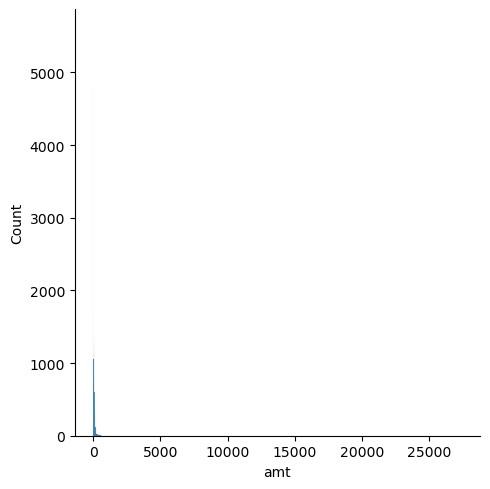

In [14]:
# Draw the distribution of numerical variables
# histogram- how many values falls into each range
# Histogram groups like:

# 10–15 → 3 values
# 16–20 → 2 values


sns.displot(data = num_df, x = 'amt')
plt.show()


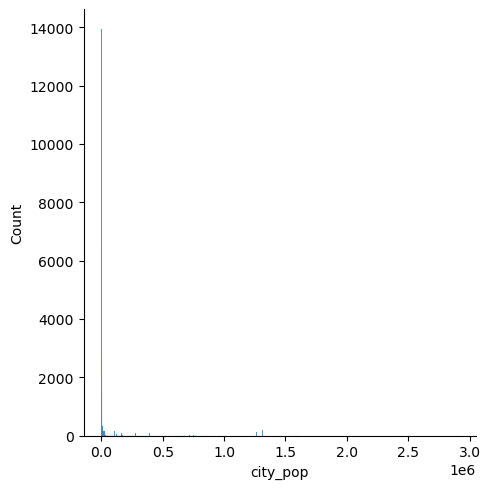

In [15]:
sns.displot(data = num_df, x = 'city_pop')
plt.show()

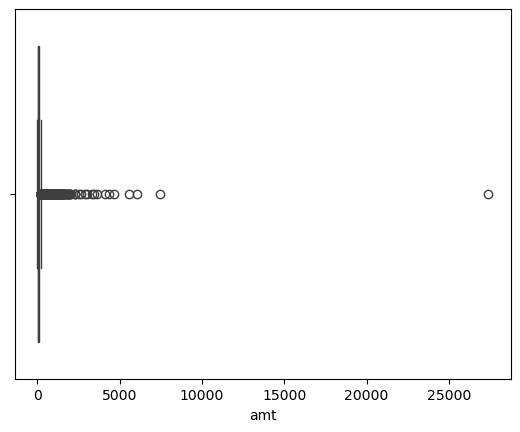

In [16]:
 # box plot

sns.boxplot(data = num_df, x = 'amt')
plt.show()

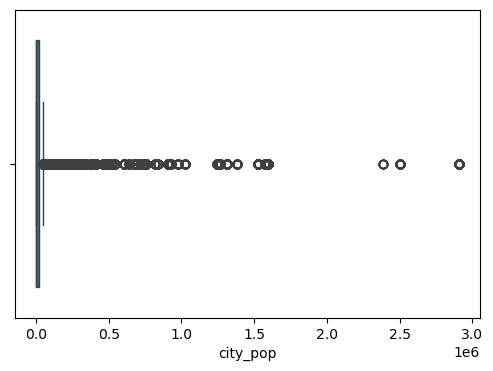

In [17]:
plt.figure(figsize=(6,4))
sns.boxplot(data = num_df, x = 'city_pop')
plt.show()

### Task 7: How does the distribution of an amt differ across is_fraud categories?

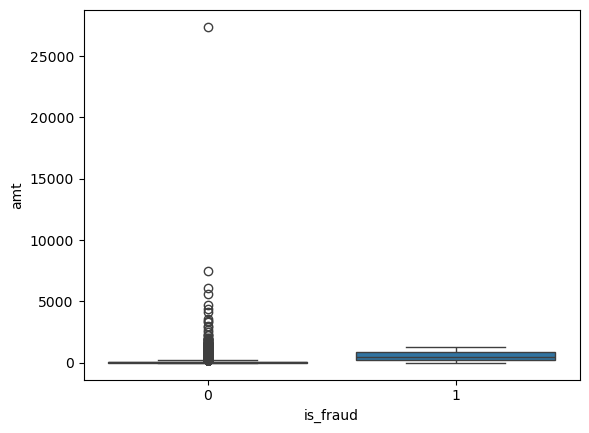

In [18]:
sns.boxplot(data = df, x = 'is_fraud', y = 'amt')
plt.show()

In [19]:
#The boxplot shows that transaction amounts differ between fraudulent and 
#non-fraudulent transactions.Non-fraudulent transactions are mostly concentrated at
#lower values, while fraudulent transactions show higher median values and greater variability.

### Task 8:Are there any outliers in the city_pop and amt?


In [20]:
# Total number of outliers in the 'amt column'
Q1 = df['amt'].quantile(0.25)
Q3 = df['amt'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q1 + 1.5 * IQR

outliers_amt = df[(df['amt'] < lower) | (df['amt'] > upper)]
print('Total outliers in amt: ',len(outliers_amt))


Total outliers in amt:  5452


In [21]:
# Total outlier in 'city_pop'
Q1 = df['city_pop'].quantile(0.25)
Q3 = df['city_pop'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers_city_pop = df[(df['city_pop'] < lower) | (df['city_pop'] > upper)]
print('Total outliers in city_pop: ',len(outliers_city_pop))

Total outliers in city_pop:  7910


### Task 9:Are there any trends or patterns in the data over time (if applicable)?

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42308 entries, 0 to 42307
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   index                  42308 non-null  int64  
 1   trans_date_trans_time  42308 non-null  object 
 2   cc_num                 42308 non-null  float64
 3   merchant               42308 non-null  object 
 4   category               42308 non-null  object 
 5   amt                    42308 non-null  float64
 6   first                  42308 non-null  object 
 7   last                   42308 non-null  object 
 8   gender                 42308 non-null  object 
 9   street                 42308 non-null  object 
 10  city                   42308 non-null  object 
 11  state                  42308 non-null  object 
 12  zip                    42308 non-null  int64  
 13  lat                    42308 non-null  float64
 14  long                   42308 non-null  float64
 15  ci

In [23]:
# convert 'trans_date_trans_time' col datatype to datetime col type
df['trans_date_trans_time'] = pd.to_datetime(df['trans_date_trans_time'])

C:\Users\anita\AppData\Local\Temp\ipykernel_32112\1066880307.py:2: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['trans_date_trans_time'] = pd.to_datetime(df['trans_date_trans_time'])


In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42308 entries, 0 to 42307
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   index                  42308 non-null  int64         
 1   trans_date_trans_time  42308 non-null  datetime64[ns]
 2   cc_num                 42308 non-null  float64       
 3   merchant               42308 non-null  object        
 4   category               42308 non-null  object        
 5   amt                    42308 non-null  float64       
 6   first                  42308 non-null  object        
 7   last                   42308 non-null  object        
 8   gender                 42308 non-null  object        
 9   street                 42308 non-null  object        
 10  city                   42308 non-null  object        
 11  state                  42308 non-null  object        
 12  zip                    42308 non-null  int64         
 13  l

In [25]:
time_df = df[['trans_date_trans_time','amt']].copy()
time_df.head(5)

,trans_date_trans_time,amt
0,2019-12-29 04:03:00,59.62
1,2019-12-31 15:47:00,9.52
2,2019-12-22 05:38:00,75.86
3,2019-12-19 23:26:00,4.03
4,2019-12-08 07:03:00,42.40


In [26]:
# if the time_df is not sorted we have to sort first
# otherwise we will get a messy graph
time_df = time_df.sort_values(by = 'trans_date_trans_time')
time_df.head(5)

,trans_date_trans_time,amt
38261,2019-12-01 00:02:00,140.44
28737,2019-12-01 00:05:00,5.01
25486,2019-12-01 00:06:00,2.53
32136,2019-12-01 00:07:00,193.88
13740,2019-12-01 00:11:00,68.80


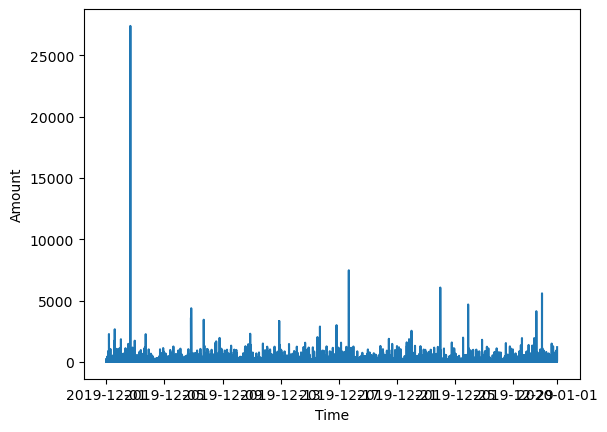

In [27]:

plt.plot(time_df['trans_date_trans_time'],time_df['amt'])
plt.xlabel('Time')
plt.ylabel('Amount')
plt.show()


In [28]:
#plt.figure(figsize=(12,6))

#sns.lineplot(x='trans_date_trans_time', y='amt', data=time_df)
#plt.show()

### Task 10:How does the target variable (if available) distribute across different categories?

In [29]:
df.columns

Index(['index', 'trans_date_trans_time', 'cc_num', 'merchant', 'category',
       'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip',
       'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'is_fraud'],
      dtype='object')

In [30]:
# target variable = o/p column(is_fraud)in our data set
# check distribution
df['is_fraud'].value_counts()

is_fraud
0    42128
1      180
Name: count, dtype: int64

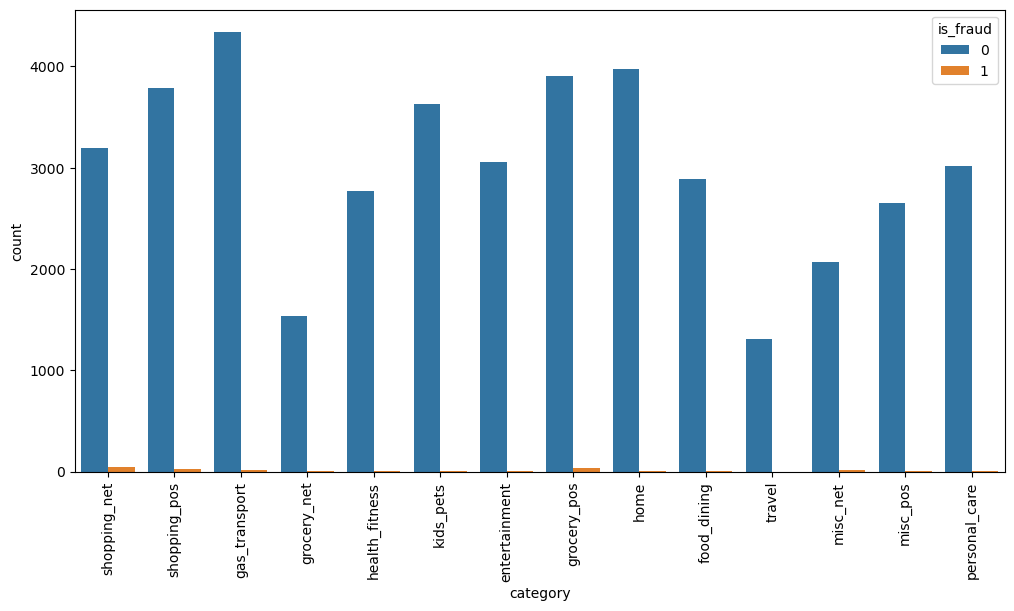

In [41]:
# Fraud across categories
# By category
plt.figure(figsize=(12,6))
sns.countplot(x='category',hue='is_fraud',data=df)
plt.xticks(rotation = 90)
plt.show()

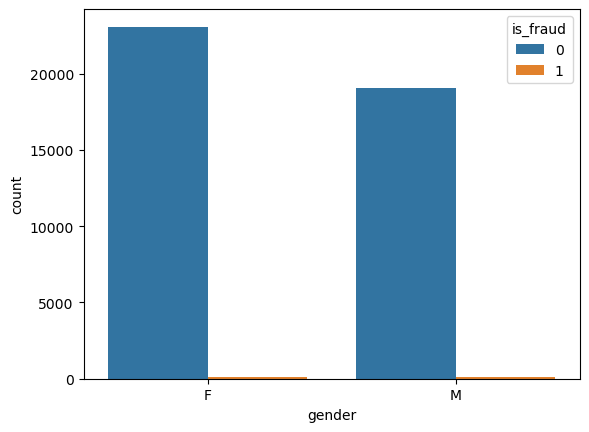

In [38]:
# by gender
sns.countplot(x='gender', hue='is_fraud', data=df)
plt.show()

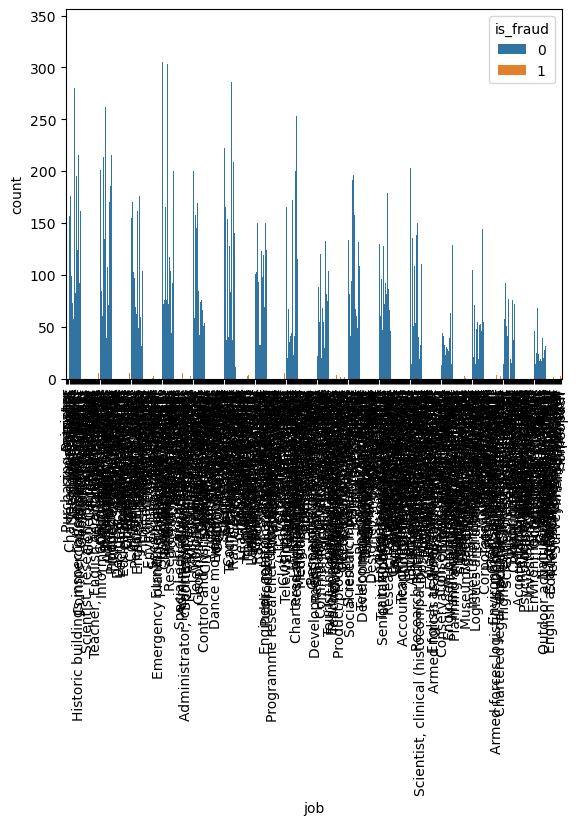

In [39]:
# By job
sns.countplot(x='job', hue='is_fraud', data=df)
plt.xticks(rotation=90)
plt.show()

In [46]:
# To avoid the overlapping
# Get top 10 jobs
top_jobs = df['job'].value_counts().nlargest(10).index
print(top_jobs)

Index(['Film/video editor', 'Surveyor, land/geomatics', 'Materials engineer',
       'Exhibition designer', 'Naval architect', 'IT trainer',
       'Financial adviser', 'Chartered public finance accountant',
       'Designer, ceramics/pottery', 'Comptroller'],
      dtype='object', name='job')


In [47]:
# Filter data
df_top = df[df['job'].isin(top_jobs)]

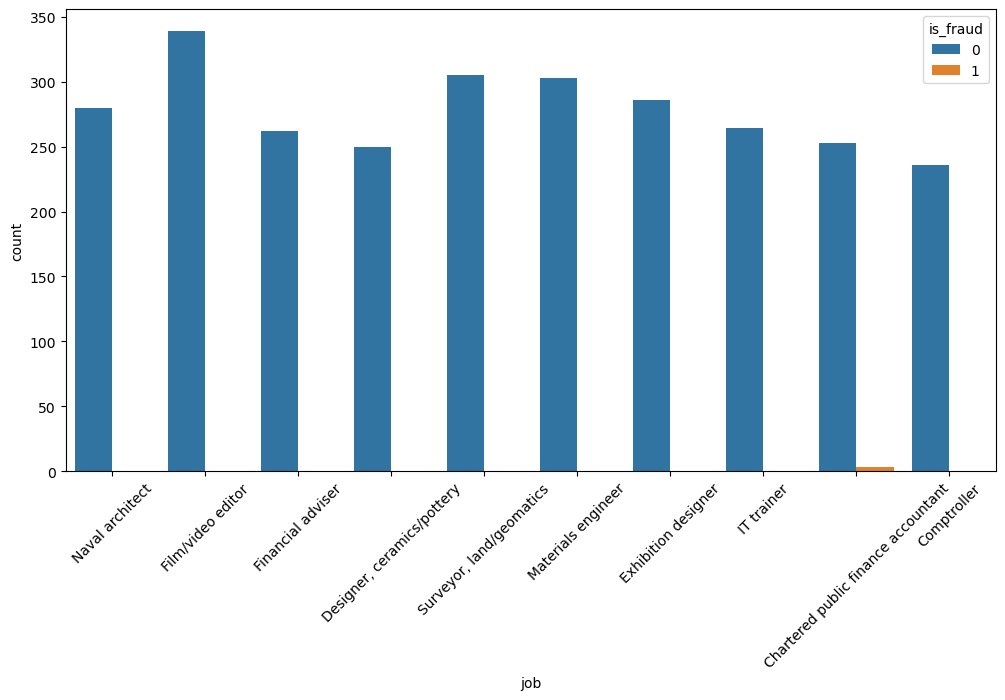

In [48]:
# Now our graph is redable
plt.figure(figsize=(12,6))
sns.countplot(x='job', hue='is_fraud', data=df_top)
plt.xticks(rotation=45)
plt.show()

### Task 11: Are there any unusual or unexpected values in the dataset that require further investigation?

In [49]:
df.columns

Index(['index', 'trans_date_trans_time', 'cc_num', 'merchant', 'category',
       'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip',
       'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'is_fraud'],
      dtype='object')

In [51]:
df['amt'].describe()

count    42308.000000
mean        70.108462
std        188.153737
min          1.000000
25%          9.590000
50%         47.440000
75%         82.910000
max      27390.120000
Name: amt, dtype: float64

In [52]:
df['city_pop'].describe()

count    4.230800e+04
mean     8.906170e+04
std      3.016427e+05
min      2.300000e+01
25%      7.430000e+02
50%      2.456000e+03
75%      2.047800e+04
max      2.906700e+06
Name: city_pop, dtype: float64

In [54]:
df['gender'].unique()

array(['F', 'M'], dtype=object)

In [55]:
df['category'].unique()

array(['shopping_net', 'shopping_pos', 'gas_transport', 'grocery_net',
       'health_fitness', 'kids_pets', 'entertainment', 'grocery_pos',
       'home', 'food_dining', 'travel', 'misc_net', 'misc_pos',
       'personal_care'], dtype=object)

In [56]:
df['job'].nunique()

480

### Task 12: Are there any potential data entry errors or inconsistencies in the dataset?


In [57]:
# No potential data entry errors and inconsistensies in the data set

### Task 13:How does the distribution of numerical variables vary between different
### groups or segments of the dataset?


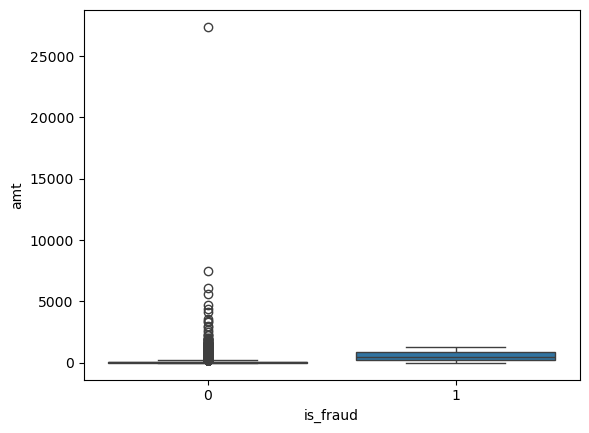

In [58]:
# Numerical variables - amt and city_pop
# segments - Categorical variable - is_fraud(target variable),Gender, State,Category
sns.boxplot(data = df, x = 'is_fraud', y = 'amt')
plt.show()

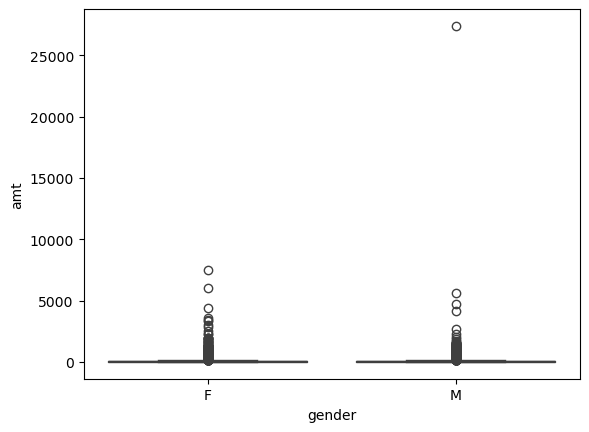

In [60]:
sns.boxplot(data = df, x = 'gender', y = 'amt')
plt.show()

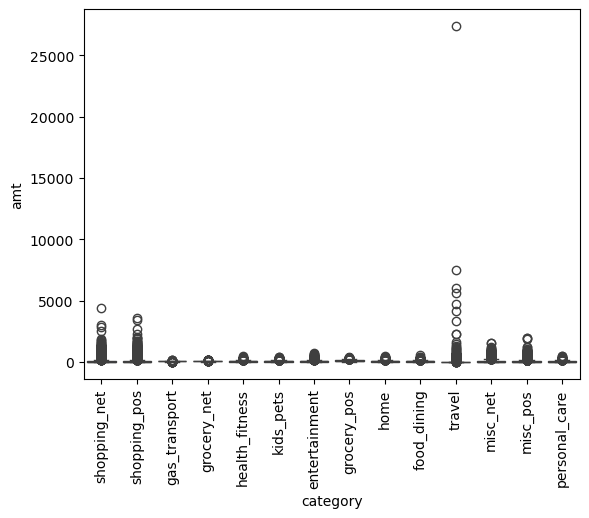

In [61]:
sns.boxplot(data = df, x = 'category', y = 'amt')
plt.xticks(rotation=90)
plt.show()

### Task 14:What are the top factors that influence the target variable, if applicable?

In [62]:
# compare amount vs fraud
df.groupby('is_fraud')['amt'].mean()

is_fraud
0     68.092670
1    541.893389
Name: amt, dtype: float64

In [63]:
# job vs fraud
pd.crosstab(df['job'], df['is_fraud'])

is_fraud,0,1
job,,
Academic librarian,33,0
"Accountant, chartered certified",20,0
"Accountant, chartered public finance",73,0
Accounting technician,129,0
Acupuncturist,61,0
...,...,...
Water engineer,186,0
Water quality scientist,23,0
Web designer,82,0


In [64]:
# correlation
df.corr(numeric_only=True)

,index,cc_num,amt,zip,lat,long,city_pop,is_fraud
index,1.000000,-0.002048,-0.008591,-0.002515,-0.002950,0.003966,0.008654,0.008780
cc_num,-0.002048,1.000000,0.002567,0.031333,-0.068048,-0.035938,-0.014689,-0.009396
amt,-0.008591,0.002567,1.000000,-0.000934,-0.002677,0.003584,-0.002109,0.163903
zip,-0.002515,0.031333,-0.000934,1.000000,-0.114818,-0.911432,0.072576,0.008430
lat,-0.002950,-0.068048,-0.002677,-0.114818,1.000000,-0.011952,-0.150619,-0.010914
long,0.003966,-0.035938,0.003584,-0.911432,-0.011952,1.000000,-0.051051,-0.000069
city_pop,0.008654,-0.014689,-0.002109,0.072576,-0.150619,-0.051051,1.000000,-0.005673
is_fraud,0.008780,-0.009396,0.163903,0.008430,-0.010914,-0.000069,-0.005673,1.000000


### Task 15: Write an analysis report on performing exploratory data analysis (EDA)
### using Python in the context of building a fraud detection system for the 
### financial industry.

In [ ]:
#The transaction amount (amt) is the most influential factor affecting the target variable (is_fraud), 
# as it shows the highest positive correlation with fraud. 
# This indicates that higher transaction amounts are more likely to be associated with fraudulent activity. 
# Other numerical variables such as city population, latitude, longitude, and credit card number show very 
# weak or negligible correlation with the target variable, suggesting they have minimal impact 
# on fraud detection.
# Therefore, transaction amount is the key factor influencing fraudulent transactions in this dataset.